###**1. IMPORT THE LIBRARIES**

In [ ]:
import matplotlib.pyplot as plt
from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
import numpy as np

import zipfile
import os
import io

import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from sklearn.metrics import classification_report, roc_curve, auc, precision_recall_curve

###**2. UPLOAD THE FILE**

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Define the path to the zipped file in Google Drive
zip_path = '/content/drive/MyDrive/CVNLP Assignment Work/images.zip'

# Define the directory where we want to extract the images
extract_path = 'images'

# Creating the extraction directory
os.makedirs(extract_path, exist_ok=True)

# Extracting the zipped file
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(f"Extraction Complete.")

Extraction Complete.


###**3. IMAGE PREPROCESSING AND DATA SPLITTING**

In [ ]:
# Image Preprocessing and Data Splitting
datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2) # Added validation_split

train_generator = datagen.flow_from_directory(
    "images", # directory is 'images'
    target_size=(128, 128), # Increased target_size for potentially larger images
    batch_size=32,
    class_mode='categorical', # class_mode is categorical for multi-class classification
    subset='training' # subset for training data
)

val_generator = datagen.flow_from_directory(
    "images", # directory is 'images'
    target_size=(128, 128), # large target_size for potentially larger images
    batch_size=32,
    class_mode='categorical', # class_mode is categorical for multi-class classification
    subset='validation' # subset for validation data
)

print(os.listdir("images")) # Changed directory to 'images'

Found 3544 images belonging to 4 classes.
Found 884 images belonging to 4 classes.
['Earthquake', 'Wildfire', 'Cyclone', 'Flood']


###**4. BULIDING CNN MODEL**

**Model Architecture**

In [ ]:
# Define the model
model = models.Sequential()
# Change the input_shape to match the target_size in ImageDataGenerator (128, 128, 3)
model.add(layers.Conv2D(32, (3,3), activation='relu', input_shape=(128, 128, 3)))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Dropout(0.25)) # Dropout to reduce overfitting

# Removed input_shape from subsequent Conv2D layers
model.add(layers.Conv2D(64, (3,3), activation='relu'))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Dropout(0.25))

model.add(layers.Conv2D(64, (3,3), activation='relu'))
model.add(layers.MaxPooling2D((2,2))) # max pooling layer to reduce dimensions further
model.add(layers.Dropout(0.25))

model.add(layers.Conv2D(64, (3,3), activation='relu')) # conv layer without immediate dropout before flattening

#Fully connected Layers
model.add(layers.Flatten())
model.add(layers.Dense(128, activation='relu'))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dropout(0.5))

#No need for softmax activation (multiclass) as from_logits=True converts to probabilities internally
model.add(layers.Dense(4)) # Output layer to 4 units for the 4 classes

#Display Architecture
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 12, 12, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,281,540 (4.89 MB)

 Trainable params: 1,281,540 (4.89 MB)

 Non-trainable params: 0 (0.00 B)

**Training Phase**

In [ ]:
#Compiling the model through a number of epochs
# Defining the Early Stopping callback
# Monitoring 'val_loss' and stop if it doesn't improve for 3 consecutive epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=3)

# Define a ModelCheckpoint callback to save weights
# Saves weights only for the best model based on validation loss
checkpoint_filepath = '/tmp/checkpoint.weights.h5'  # Define a path to save the weights
model_checkpoint_callback = ModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True,
    monitor='val_loss',
    mode='min',
    save_best_only=True)

model.compile(optimizer='adam',
              loss=tf.keras.losses.CategoricalCrossentropy(from_logits=True), #CategoricalCrossentropy
              metrics=['accuracy'])

# Initializing variables to store the best epoch and corresponding metrics
best_epoch = 0
best_val_loss = float('inf') # We initialize with a very large value
best_val_accuracy = 0.0

# Passing the early_stopping callback to the callbacks argument
history = model.fit(train_generator, # use train_generator
                    epochs=15,
                    validation_data=val_generator, # use val_generator
                    callbacks=[early_stopping, model_checkpoint_callback]) # Add the callbacks

# We find the index of the minimum validation loss.
if history.history['val_loss']:
    best_epoch_index = history.history['val_loss'].index(min(history.history['val_loss']))
    best_epoch = best_epoch_index + 1 # Epochs are 1-indexed, list indices are 0-indexed
    best_val_loss = history.history['val_loss'][best_epoch_index]
    best_val_accuracy = history.history['val_accuracy'][best_epoch_index]

    print(f"Best epoch selected for prediction and evaluation is Epoch {best_epoch}")
    print(f"Validation Loss: {best_val_loss:.4f}")
    print(f"Validation Accuracy: {best_val_accuracy:.4f}")
else:
    print("Training history is empty. Could not determine the best epoch.")

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
111/111 ━━━━━━━━━━━━━━━━━━━━ 65s 532ms/step - accuracy: 0.2899 - loss: 1.3912 - val_accuracy: 0.5294 - val_loss: 1.0252
Epoch 2/15
111/111 ━━━━━━━━━━━━━━━━━━━━ 61s 552ms/step - accuracy: 0.5405 - loss: 1.0728 - val_accuracy: 0.7387 - val_loss: 0.7137
Epoch 3/15
111/111 ━━━━━━━━━━━━━━━━━━━━ 53s 480ms/step - accuracy: 0.6880 - loss: 0.8528 - val_accuracy: 0.7229 - val_loss: 0.7074
Epoch 4/15
111/111 ━━━━━━━━━━━━━━━━━━━━ 50s 456ms/step - accuracy: 0.7353 - loss: 0.7686 - val_accuracy: 0.7636 - val_loss: 0.6373
Epoch 5/15
111/111 ━━━━━━━━━━━━━━━━━━━━ 59s 536ms/step - accuracy: 0.7662 - loss: 0.6653 - val_accuracy: 0.7523 - val_loss: 0.6575
Epoch 6/15
111/111 ━━━━━━━━━━━━━━━━━━━━ 49s 441ms/step - accuracy: 0.7919 - loss: 0.6392 - val_accuracy: 0.8111 - val_loss: 0.5486
Epoch 7/15
111/111 ━━━━━━━━━━━━━━━━━━━━ 50s 448ms/step - accuracy: 0.8139 - loss: 0.5527 - val_accuracy: 0.8518 - val_loss: 0.4372
Epoch 8/15
111/111 ━━━━━━━━━━━━━━━━━━━━ 49s 440ms/step - accuracy: 0.8386 - loss: 0

###**5. PERFORMANCE AND EVALUATION**

**Accuracy over each epoch**

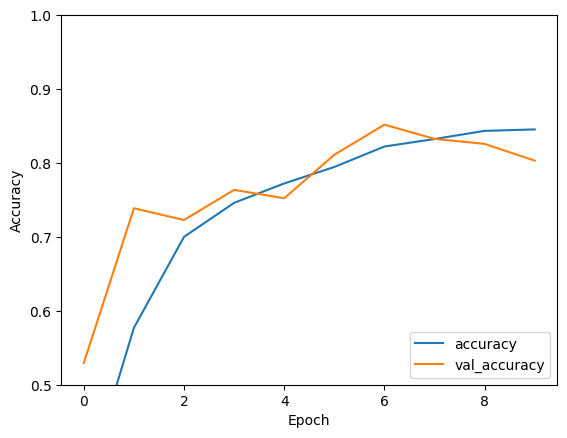

In [ ]:
# Plotting accuracy vs Epoch
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')

**Classification and Confusion Matrix**

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 278ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━

<Figure size 1000x800 with 0 Axes>

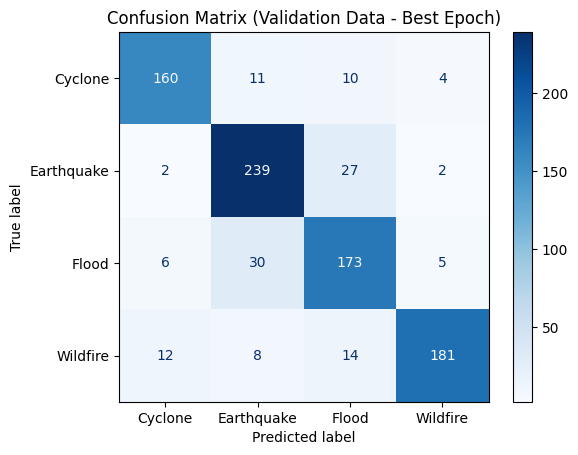

In [ ]:
# Plotting the Confusion Matrix and Classification Report
# Loading the best weights from the checkpoint file
model.load_weights(checkpoint_filepath)

# predictions and true labels from val_generator for confusion matrix and classification report
val_labels = []
val_predictions = []
for i in range(len(val_generator)):
    images, labels = next(val_generator)
    val_labels.extend(np.argmax(labels, axis=1))
    predictions = model.predict(images)
    val_predictions.extend(np.argmax(predictions, axis=1))

# Classification Report
class_names = list(val_generator.class_indices.keys())
report = classification_report(val_labels, val_predictions, target_names=class_names)
print("\nClassification Report (Validation Data - Best Epoch):")
print(report)

# Computing the confusion matrix using validation data
cm = confusion_matrix(val_labels, val_predictions)

# Plotting the confusion matrix
plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix (Validation Data - Best Epoch)') # Updated title
plt.show()

**Plotting AUC-ROC curve**

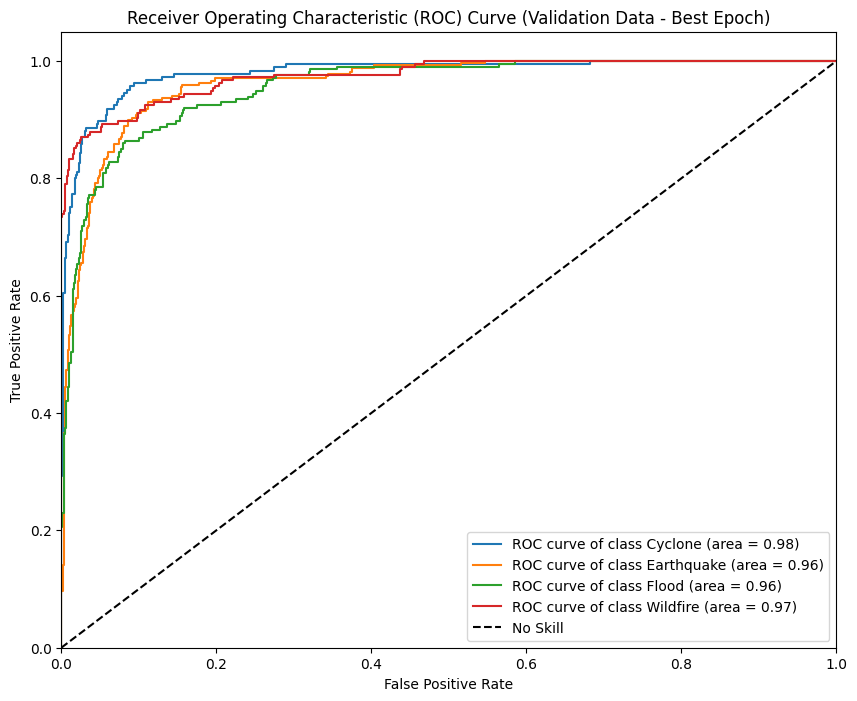


AUC Scores (Validation Data - Best Epoch):
Class Cyclone: 0.9799
Class Earthquake: 0.9623
Class Flood: 0.9555
Class Wildfire: 0.9744


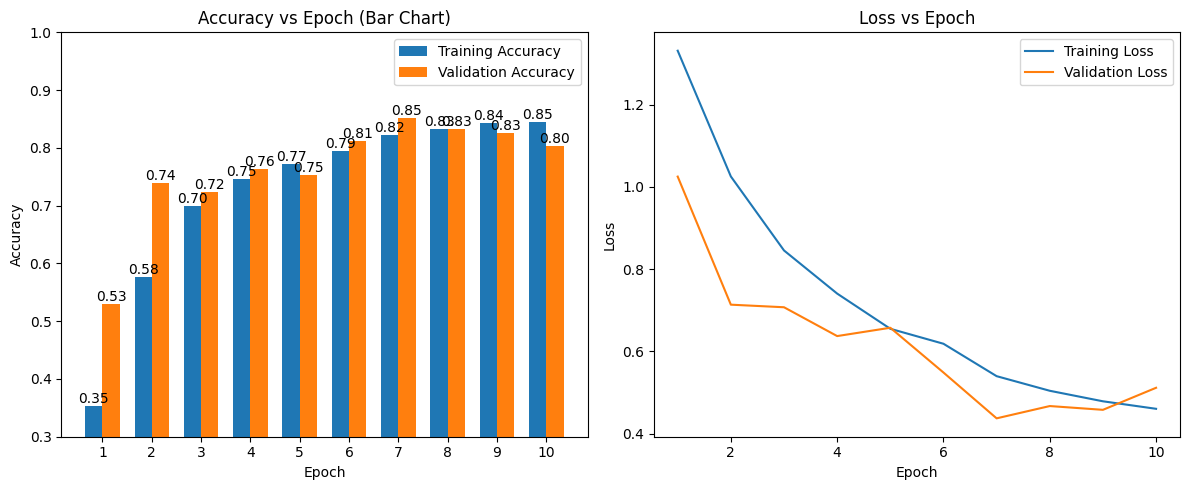

In [ ]:
# Collect True Labels and Predictions/Probabilities for Validation Set
# Collect all true labels, predicted classes, and predicted probabilities from the validation generator
val_labels_all = []
val_predictions_all = []
val_probabilities_all = []

val_generator.reset() # Resets the generator before iterating

for i in range(len(val_generator)):
    images, labels = next(val_generator)
    val_labels_all.extend(np.argmax(labels, axis=1)) # Stores the true class indices
    predictions = model.predict(images, verbose=0) # Gets our raw predictions
    val_predictions_all.extend(np.argmax(predictions, axis=1)) # Stores our predicted class indices
    val_probabilities_all.extend(tf.nn.softmax(predictions).numpy()) # Stores our predicted probabilities after softmax

val_labels_all = np.array(val_labels_all)
val_predictions_all = np.array(val_predictions_all)
val_probabilities_all = np.array(val_probabilities_all)

class_names = list(val_generator.class_indices.keys()) # Gets the 4 class names


#Plotting ROC Curve and AUC Scores
# Calculating ROC curve and AUC for each class
n_classes = len(class_names)
fpr = dict()
tp = dict()
roc_auc = dict()

# Converting true labels to one-hot encoding for AUC calculation
val_labels_one_hot = tf.keras.utils.to_categorical(val_labels_all, num_classes=n_classes)

for i in range(n_classes):
    try:
        # Using the collected true labels and probabilities for AUC calculation
        fpr[i], tp[i], _ = roc_curve(val_labels_one_hot[:, i], val_probabilities_all[:, i])
        roc_auc[i] = auc(fpr[i], tp[i])
    except ValueError:
        # Handling the cases where a class might not be present or other issues
        roc_auc[i] = np.nan # Appending NaN if AUC cannot be calculated

# Plotting the ROC curves
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    if not np.isnan(roc_auc[i]): # Only plot if AUC was successfully calculated
        plt.plot(fpr[i], tp[i], label='ROC curve of class {0} (area = {1:0.2f})'
                                       ''.format(class_names[i], roc_auc[i]))
plt.plot([0, 1], [0, 1], 'k--', label='No Skill')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve (Validation Data - Best Epoch)') # Updated title
plt.legend(loc="lower right")
plt.show()

# Printing AUC Scores
print("\nAUC Scores (Validation Data - Best Epoch):")
for i in range(n_classes):
    if not np.isnan(roc_auc[i]):
        print(f"Class {class_names[i]}: {roc_auc[i]:.4f}")
    else:
        print(f"Class {class_names[i]}: AUC could not be calculated")


# Plotting Accuracy vs Epoch as a Bar Chart
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
epochs = range(1, len(history.history['accuracy']) + 1) # Get epoch numbers
bar_width = 0.35 # Width of the bars
train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

bars1 = plt.bar([e - bar_width/2 for e in epochs], train_acc, bar_width, label='Training Accuracy') # Plot training accuracy as bars
bars2 = plt.bar([e + bar_width/2 for e in epochs], val_acc, bar_width, label='Validation Accuracy') # Plot validation accuracy as bars

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Epoch (Bar Chart)') # Updated title
plt.xticks(epochs) # Set x-ticks to be the epoch numbers
plt.ylim([0.3, 1]) # Limit y-axis from 0.3 to 1
plt.legend()

# Annotate the bars with their values
def autolabel(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height,
                 f'{height:.2f}',
                 ha='center', va='bottom')

autolabel(bars1)
autolabel(bars2)


# Plotting Loss vs Epoch (Keeping as line plot for comparison)
plt.subplot(1, 2, 2)
plt.plot(epochs, history.history['loss'], label='Training Loss') # Use epoch numbers
plt.plot(epochs, history.history['val_loss'], label='Validation Loss') # Use epoch numbers
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss vs Epoch')
plt.legend()

plt.tight_layout()
plt.show()

###**6. PREDICTING UNSEEN IMAGE**

Saving Flood.jpeg to Flood.jpeg


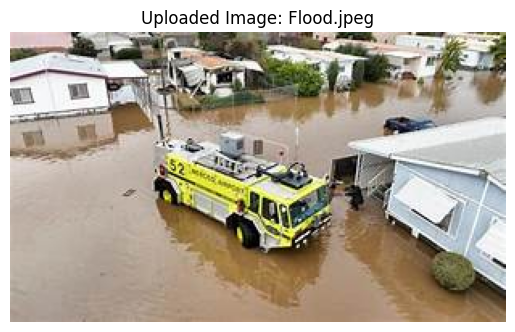

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 259ms/step
Uploaded file: Flood.jpeg
Predicted class: Flood
Confidence score: 0.9948


In [ ]:
def predict_single_image(model, img_path, target_size=(128, 128)):
    img = image.load_img(img_path, target_size=target_size)
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) # Create a batch
    img_array /= 255.0  # rescaling the image

    predictions = model.predict(img_array)
    # Since the last layer has no activation and from_logits=True was used in loss,
    # we apply softmax to get probabilities
    probabilities = tf.nn.softmax(predictions[0]).numpy()

    predicted_class_index = np.argmax(probabilities)
    confidence_score = probabilities[predicted_class_index]

    # Getting the class name from the generator's class indices
    class_indices = train_generator.class_indices # i'm using train_generator to get class indices
    class_names = list(class_indices.keys())
    predicted_class_name = class_names[predicted_class_index]

    return predicted_class_name, confidence_score

# Example usage with file upload:
uploaded = files.upload()

for fn in uploaded.keys():
    # Saving the uploaded file
    with open(fn, 'wb') as f:
        f.write(uploaded[fn])

    # Displaying the uploaded image
    img = image.load_img(fn)
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"Uploaded Image: {fn}")
    plt.show()

    # Making prediction using our cnn
    predicted_class, confidence = predict_single_image(model, fn) # Use the 'model' object from previous cells

    print(f"Uploaded file: {fn}")
    print(f"Predicted class: {predicted_class}")
    print(f"Confidence score: {confidence:.4f}")